# Clouds and CHL: how errors depend on cloud history, season and gap size

Uses the checkpointed predictions in `models/*/preds.npz` (no retraining). All scores are on the fixed hidden test pixels (test years 2004, 2010, 2016, 2020) in ln CHL units, so the rows are comparable with `cnn_results.ipynb`.

**Assumptions.** "Cloudy" means no L3 CHL value at an ocean pixel (the L3 gap mask; it also includes sun-glint and other flags, not only cloud). Gap length before a scored day is counted in the real record, so it is the length of the real cloudy spell that ended on the scored day. Models with temporal context also see the donor's clouds on the neighbouring days, so their inputs on days t±1, t±2 can be hidden even when the real record is clear. Days absent from the record (no CHL anywhere) count as cloudy.

Questions:
1. Does the error grow with the length of the cloudy spell that preceded the scored day?
2. Is the error different in monsoon months and at pixels that are cloudy most of the time?
3. Does the error depend on how large the gap is around the pixel in the input?
4. Independent of any model: is CHL on the first clear day after a long cloudy spell different from climatology?


In [1]:
def _has_preds(r):
    try: return (find_run(r) / "preds.npz").exists()
    except FileNotFoundError: return False
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent))
from chl_cnn import data as D, store as S
from chl_cnn.plotting import OKABE_ITO as OI
from scipy.ndimage import uniform_filter

from chl_cnn.runs import find_run
RUNS = [r for r in ["full_alldays_fakeclouds", "perf_dilated_base", "perf_dilated_ctx2", "perf_dilated_allfeat", "perf_unet32_l1"]
        if _has_preds(r)]
d = S.load_store(); times = pd.to_datetime(d["time"]); ocean = d["ocean"]; lat, lon = d["lat"], d["lon"]
tr, va, te = D.split_by_years(d["time"])
obs_all = np.zeros((len(times),) + ocean.shape, bool)          # observed (ocean & finite) for every day, ~230 MB
for b in range(0, len(times), 500):
    obs_all[b:b + 500] = np.isfinite(np.asarray(d["chl_l3"][b:b + 500])) & ocean
y_te = D.log_chl(np.asarray(d["chl_l3"][te]))
z = np.load(find_run(RUNS[0]) / "preds.npz"); hid = z["hidden"][len(va):]; assert (z["test_idx"] == te).all()
err = {}
for r in RUNS:
    z = np.load(find_run(r) / "preds.npz"); assert (z["hidden"][len(va):] == hid).all()
    err[r] = np.where(hid, z["pred"][len(va):] - y_te, np.nan).astype("float32")   # signed error on hidden pixels
clim_bins = None
print(RUNS); print(f"{len(te)} test days, {int(hid.sum())} hidden pixels")

['full_alldays_fakeclouds', 'perf_dilated_base', 'perf_dilated_ctx2']
1463 test days, 5522954 hidden pixels


## 1. Error vs length of the real cloudy spell before the scored day

For each hidden test pixel, count the consecutive days before day t on which the pixel had no observation (calendar days; capped at 15). Days missing from the record count as cloudy.

,gap_days,mae_full_alldays_fakeclouds,mae_perf_dilated_base,mae_perf_dilated_ctx2,n_pixels
0,0,0.247,0.180,0.149,2941654
1,1,0.224,0.161,0.135,1003944
2,2,0.225,0.159,0.137,497412
3,3-4,0.224,0.158,0.135,487347
4,5-7,0.228,0.158,0.134,295115
5,8-14,0.241,0.166,0.141,200964
6,>=15,0.306,0.211,0.188,96518


,gap_days,bias_full_alldays_fakeclouds,bias_perf_dilated_base,bias_perf_dilated_ctx2,n_pixels
0,0,-0.030,-0.031,-0.009,2941654
1,1,-0.039,-0.028,-0.011,1003944
2,2,-0.050,-0.025,-0.013,497412
3,3-4,-0.065,-0.029,-0.015,487347
4,5-7,-0.088,-0.030,-0.015,295115
5,8-14,-0.118,-0.034,-0.018,200964
6,>=15,-0.172,-0.035,-0.023,96518


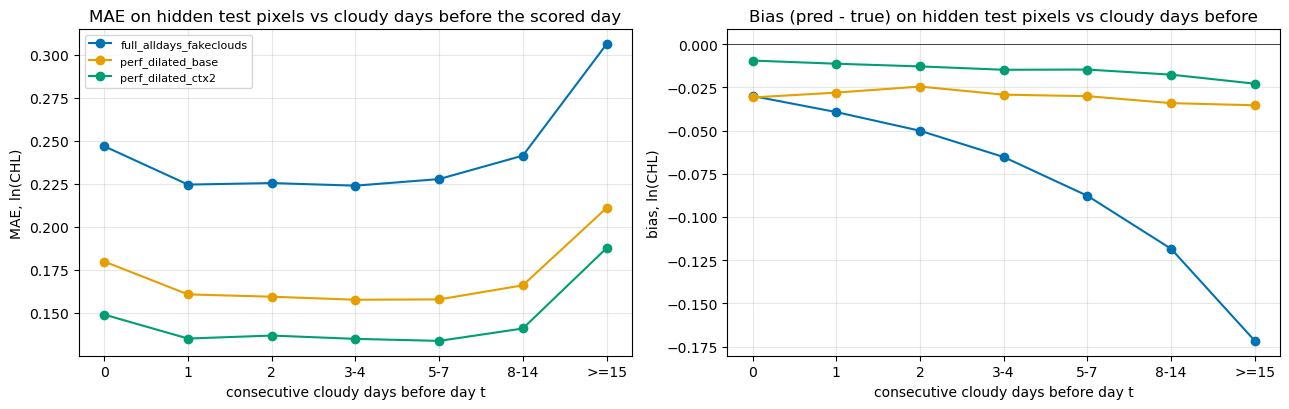

In [2]:
days = times.values.astype("datetime64[D]").astype(int); lut = {int(x): i for i, x in enumerate(days)}
CAP = 15
def obs_on(day_int):
    i = lut.get(day_int); return obs_all[i] if i is not None else np.zeros(ocean.shape, bool)
gap = np.zeros((len(te),) + ocean.shape, np.int16)               # cloudy days immediately before day t
for k, i in enumerate(te):
    run = np.zeros(ocean.shape, np.int16); alive = np.ones(ocean.shape, bool)
    for back in range(1, CAP + 1):
        o = obs_on(int(days[i]) - back); alive &= ~o; run += alive
    gap[k] = run
edges = [0, 1, 2, 3, 5, 8, 15, 16]; labels = ["0", "1", "2", "3-4", "5-7", "8-14", ">=15"]
gb = np.digitize(gap, edges[1:-1]) if False else np.searchsorted(edges[1:], gap, side="right")
rows = []
for b, lab in enumerate(labels):
    m = hid & (gb == b)
    row = dict(gap_days=lab, n_pixels=int(m.sum()))
    for r in RUNS: row[f"mae_{r}"] = float(np.nanmean(np.abs(err[r][m]))); row[f"bias_{r}"] = float(np.nanmean(err[r][m]))
    rows.append(row)
tab = pd.DataFrame(rows); display(tab[["gap_days"] + [c for c in tab if c.startswith("mae")] + ["n_pixels"]].round(3)); display(tab[["gap_days"] + [c for c in tab if c.startswith("bias")] + ["n_pixels"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for j, r in enumerate(RUNS):
    axes[0].plot(labels, tab[f"mae_{r}"], marker="o", color=OI[j], label=r); axes[1].plot(labels, tab[f"bias_{r}"], marker="o", color=OI[j], label=r)
axes[0].set(title="MAE on hidden test pixels vs cloudy days before the scored day", xlabel="consecutive cloudy days before day t", ylabel="MAE, ln(CHL)")
axes[1].axhline(0, color="k", lw=.5); axes[1].set(title="Bias (pred - true) on hidden test pixels vs cloudy days before", xlabel="consecutive cloudy days before day t", ylabel="bias, ln(CHL)")
for ax in axes: ax.grid(alpha=.3)
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

## 2. Error by month and by how often a pixel is cloudy

Pixel cloud frequency = fraction of all 8,461 days without an observation at that pixel (1997-2020).

,month,cloud_frac_test_days,n_pixels,mae_full_alldays_fakeclouds,mae_perf_dilated_base,mae_perf_dilated_ctx2
0,1,0.561,566039,0.236,0.168,0.145
1,2,0.556,552091,0.266,0.197,0.170
2,3,0.545,602468,0.210,0.155,0.130
3,4,0.538,578760,0.162,0.113,0.095
4,5,0.675,434412,0.212,0.141,0.117
5,6,0.759,293984,0.218,0.144,0.122
6,7,0.828,228519,0.251,0.170,0.152
7,8,0.798,259301,0.279,0.203,0.170
8,9,0.739,321833,0.328,0.240,0.202
9,10,0.584,537600,0.304,0.211,0.168


,pixel_cloud_freq,n_pixels,mae_full_alldays_fakeclouds,mae_perf_dilated_base,mae_perf_dilated_ctx2
0,0.0-0.5,5115,0.471,0.347,0.292
1,0.5-0.6,309654,0.446,0.334,0.288
2,0.6-0.7,2163727,0.248,0.185,0.157
3,0.7-0.8,2770940,0.200,0.138,0.114
4,0.8-0.9,273143,0.311,0.209,0.173
5,0.9-1.0,375,1.303,0.576,0.580


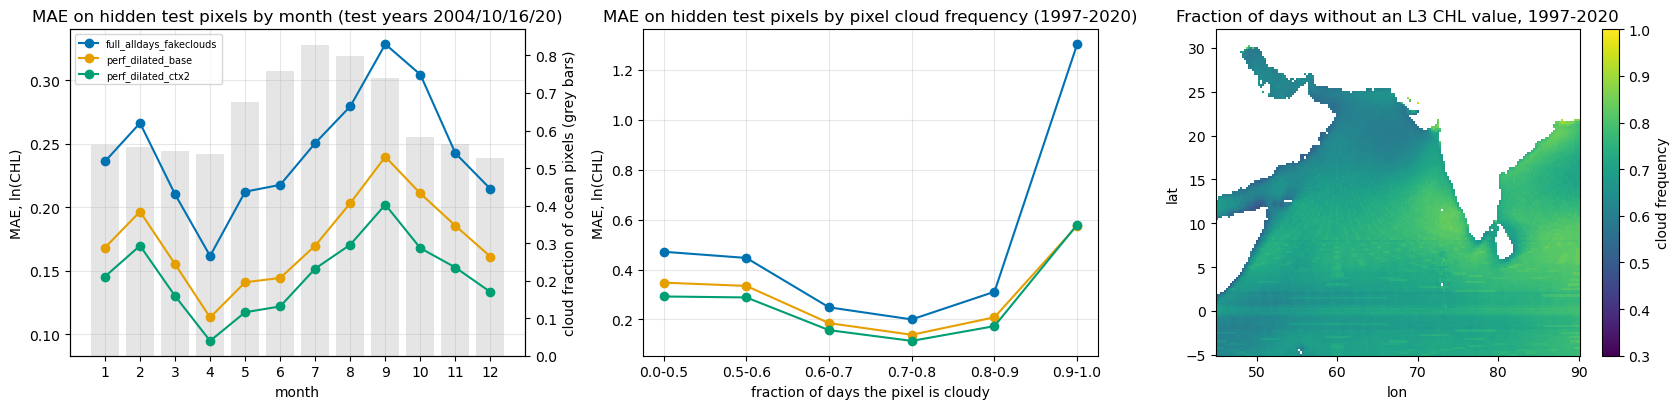

In [3]:
mon = times[te].month.values
rows = []
for m_ in range(1, 13):
    sel = mon == m_; mm = hid[sel]
    row = dict(month=m_, cloud_frac_test_days=float(1 - obs_all[te][sel][:, ocean].mean()), n_pixels=int(mm.sum()))
    for r in RUNS: row[f"mae_{r}"] = float(np.nanmean(np.abs(err[r][sel][mm])))
    rows.append(row)
tm = pd.DataFrame(rows); display(tm.round(3))
cloud_freq = 1 - obs_all[:, :, :].mean(0); cloud_freq[~ocean] = np.nan
cf_edges = [0, .5, .6, .7, .8, .9, 1.0]
cfb = np.searchsorted(cf_edges[1:], cloud_freq, side="right")
rows = []
for b in range(len(cf_edges) - 1):
    m = hid & (cfb == b)[None]
    row = dict(pixel_cloud_freq=f"{cf_edges[b]:.1f}-{cf_edges[b + 1]:.1f}", n_pixels=int(m.sum()))
    for r in RUNS: row[f"mae_{r}"] = float(np.nanmean(np.abs(err[r][m]))) if m.any() else np.nan
    rows.append(row)
tc = pd.DataFrame(rows); display(tc.round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for j, r in enumerate(RUNS):
    axes[0].plot(tm.month, tm[f"mae_{r}"], marker="o", color=OI[j], label=r); axes[1].plot(tc.pixel_cloud_freq, tc[f"mae_{r}"], marker="o", color=OI[j], label=r)
ax2 = axes[0].twinx(); ax2.bar(tm.month, tm.cloud_frac_test_days, color="0.8", alpha=.5, zorder=0); ax2.set_ylabel("cloud fraction of ocean pixels (grey bars)")
axes[0].set(title="MAE on hidden test pixels by month (test years 2004/10/16/20)", xlabel="month", ylabel="MAE, ln(CHL)", xticks=range(1, 13)); axes[0].set_zorder(1); axes[0].patch.set_visible(False)
axes[1].set(title="MAE on hidden test pixels by pixel cloud frequency (1997-2020)", xlabel="fraction of days the pixel is cloudy", ylabel="MAE, ln(CHL)")
im = axes[2].pcolormesh(lon, lat, cloud_freq, cmap="viridis", vmin=.3, vmax=1, shading="auto"); fig.colorbar(im, ax=axes[2], label="cloud frequency")
axes[2].set(title="Fraction of days without an L3 CHL value, 1997-2020", xlabel="lon", ylabel="lat")
for ax in axes[:2]: ax.grid(alpha=.3)
axes[0].legend(fontsize=7); fig.tight_layout(); plt.show()

## 3. Error vs size of the gap around the pixel in the input

Local gap size = fraction of pixels without a value in the model input (real and fake clouds together) within an 11 x 11 window (~2.75°, 300 km) around the scored pixel.

,local_gap,n_pixels,mae_full_alldays_fakeclouds,mae_perf_dilated_base,mae_perf_dilated_ctx2
0,0.0-0.2,13165,0.103,0.092,0.089
1,0.2-0.4,86225,0.100,0.088,0.085
2,0.4-0.6,287505,0.110,0.095,0.090
3,0.6-0.8,752494,0.126,0.105,0.098
4,0.8-0.9,738817,0.154,0.122,0.108
5,0.9-1.0,3644748,0.293,0.203,0.166


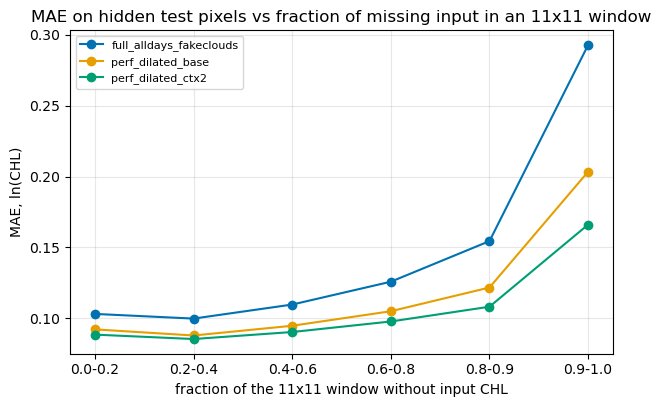

In [4]:
vis = obs_all[te] & ~hid
local_gap = np.stack([1 - uniform_filter(v.astype("float32"), size=11, mode="nearest") for v in vis])
lg_edges = [0, .2, .4, .6, .8, .9, 1.01]
lgb = np.searchsorted(lg_edges[1:], local_gap, side="right")
rows = []
for b in range(len(lg_edges) - 1):
    m = hid & (lgb == b)
    row = dict(local_gap=f"{lg_edges[b]:.1f}-{min(lg_edges[b + 1], 1):.1f}", n_pixels=int(m.sum()))
    for r in RUNS: row[f"mae_{r}"] = float(np.nanmean(np.abs(err[r][m]))) if m.any() else np.nan
    rows.append(row)
tl = pd.DataFrame(rows); display(tl.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
for j, r in enumerate(RUNS): ax.plot(tl.local_gap, tl[f"mae_{r}"], marker="o", color=OI[j], label=r)
ax.set(title="MAE on hidden test pixels vs fraction of missing input in an 11x11 window", xlabel="fraction of the 11x11 window without input CHL", ylabel="MAE, ln(CHL)")
ax.grid(alpha=.3); ax.legend(fontsize=8); plt.show()

## 4. Data only: CHL on the first clear day after a cloudy spell

Anomaly = ln CHL minus the pixel's day-of-year climatology (8-day bins, 40-day smoothing, training days only, as in `train2.py`). For every observed ocean pixel-day in the test years, group by the number of cloudy days that preceded it. If clouds (or the weather that comes with them) lower CHL, the anomaly should fall with the spell length. This uses no model.

,gap_days,mean_anomaly,median_anomaly,sd,n_pixels
0,0,-0.012,-0.041,0.435,4721881
1,1,0.015,-0.013,0.405,1612936
2,2,0.037,0.008,0.403,785485
3,3-4,0.054,0.024,0.396,764336
4,5-7,0.087,0.054,0.391,455946
5,8-14,0.125,0.086,0.401,305776
6,>=15,0.142,0.093,0.493,144890


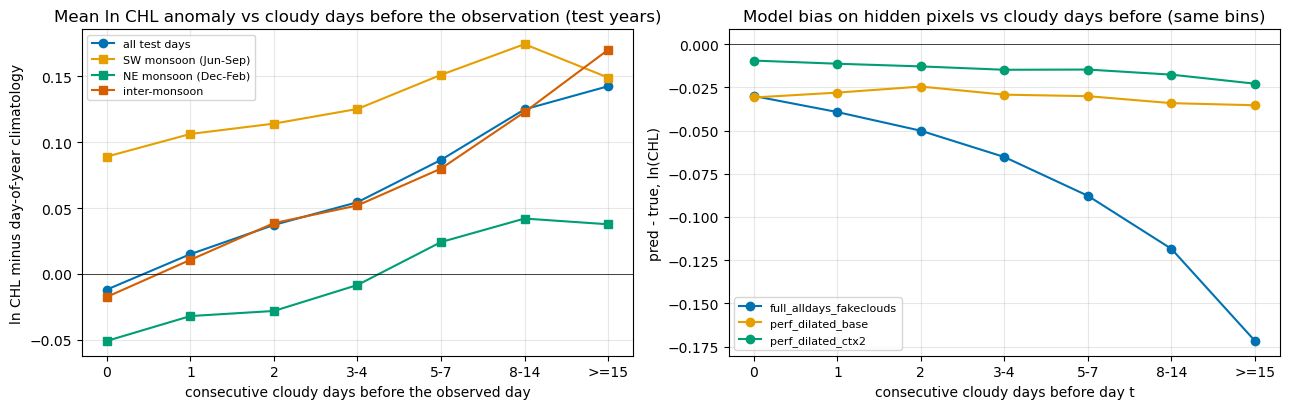

In [5]:
from chl_cnn.train2 import doy_climatology
import chl_cnn.train2 as T2; T2.TIMES = d["time"]
y_tr_sample = None
clim, dbin = doy_climatology(D.log_chl(np.asarray(d["chl_l3"])), obs_all, tr)
anom = y_te - clim[dbin[te]]
rows = []
for b, lab in enumerate(labels):
    m = obs_all[te] & (gb == b)
    a = anom[m]
    rows.append(dict(gap_days=lab, mean_anomaly=float(np.nanmean(a)), median_anomaly=float(np.nanmedian(a)), sd=float(np.nanstd(a)), n_pixels=int(np.isfinite(a).sum())))
ta = pd.DataFrame(rows); display(ta.round(3))
# same, split by season
seas = {"SW monsoon (Jun-Sep)": np.isin(mon, [6, 7, 8, 9]), "NE monsoon (Dec-Feb)": np.isin(mon, [12, 1, 2]), "inter-monsoon": np.isin(mon, [3, 4, 5, 10, 11])}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(labels, ta.mean_anomaly, marker="o", color=OI[0], label="all test days")
for j, (name, sel) in enumerate(seas.items()):
    vals = [float(np.nanmean(anom[sel][obs_all[te][sel] & (gb[sel] == b)])) for b in range(len(labels))]
    axes[0].plot(labels, vals, marker="s", color=OI[j + 1], label=name)
axes[0].axhline(0, color="k", lw=.5); axes[0].set(title="Mean ln CHL anomaly vs cloudy days before the observation (test years)", xlabel="consecutive cloudy days before the observed day", ylabel="ln CHL minus day-of-year climatology")
axes[0].grid(alpha=.3); axes[0].legend(fontsize=8)
for j, r in enumerate(RUNS):
    axes[1].plot(labels, tab[f"bias_{r}"], marker="o", color=OI[j], label=r)
axes[1].axhline(0, color="k", lw=.5); axes[1].set(title="Model bias on hidden pixels vs cloudy days before (same bins)", xlabel="consecutive cloudy days before day t", ylabel="pred - true, ln(CHL)"); axes[1].grid(alpha=.3); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## Observations

Runs available at execution time: `full_alldays_fakeclouds` (previous CNN), `perf_dilated_base`, `perf_dilated_ctx2`. Re-run the notebook once the remaining `perf_*` runs finish to add them.

**1. Cloudy spell before the scored day.** MAE is flat for spells of 1-14 days (ctx2: 0.134-0.141) and rises only for spells of 15+ days (0.188; n = 96,518 px, 1.7 % of scored pixels). Pixels observed on the previous day (spell 0) score slightly *worse* than pixels after a short spell (0.149 vs 0.135). The previous CNN's bias grows steadily negative with spell length (-0.03 at 0 days to -0.17 at 15+ days, i.e. it under-predicts after long cloudy spells); the new models stay within -0.01 to -0.035.

**2. Month and pixel cloud frequency.** MAE has a strong seasonal cycle: lowest in April (ctx2 0.095), highest in September-October (0.20, 0.17), i.e. it peaks just *after* the cloudiest months (July-August, 80 % of ocean pixels cloudy). By pixel cloud frequency the error is U-shaped: lowest for the bulk of pixels (70-80 % cloudy, 0.114), 2.5x higher for the rarely-cloudy pixels (< 60 % cloudy: 0.29, n = 315 k; these are the Persian Gulf, Red Sea and Gulf of Aden areas on the map) and higher again for the 80-90 % group (0.173). The 90-100 % group has 375 pixels only.

**3. Local gap size in the input.** The single strongest dependence. With less than 60 % of the 11x11 window missing, all three models score 0.085-0.11; with more than 90 % missing, 0.166 (ctx2), 0.203 (base), 0.293 (previous CNN). Two thirds of all scored pixels (3.6 M of 5.5 M) are in that last bin, because donor cloud masks are large, so the overall score is mostly a large-gap score. Temporal context helps most exactly there (0.203 to 0.166).

**4. CHL after a cloudy spell, no model.** The mean ln CHL anomaly on the first clear day rises with the length of the preceding cloudy spell: -0.01 after 0 days, +0.05 after 3-4 days, +0.14 after 15+ days (about 15 % above climatology; n = 145 k). The rise is present in all seasons and largest in the SW monsoon (+0.09 to +0.17). The sign is opposite to a pure light-limitation effect (which would lower CHL under long cloud cover). The previous CNN's negative bias after long spells matches this: it predicted climatology-like values where the observed values were elevated.

**Caveats.** Every scored pixel was observable on its day; nothing here measures skill on pixels that stayed cloudy. "Cloudy" is the L3 gap mask (cloud, glint, other flags). Spell length was counted on calendar days, with days absent from the record treated as cloudy. Groups are large (all n > 300 except the 90-100 % cloud-frequency bin), but the anomaly analysis in 4 conditions on observability and is descriptive; it does not separate light from the co-varying wind, mixing and upwelling.
